# AI & ML Internship - Task 1
## Data Cleaning & Preprocessing

This notebook demonstrates data cleaning and preprocessing using the Titanic dataset.

In [9]:
# AI & ML Internship - Task 1
# Data Cleaning & Preprocessing

## Step 0: Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

## Step 1: Load Dataset

In [11]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("First 5 rows of dataset:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
print(df.describe(include="all"))

First 5 rows of dataset:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8

## Step 2: Handle Missing Values

In [12]:
print("\nMissing Values Before Handling:")
print(df.isnull().sum())

# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with the mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin because it contains many missing values
df = df.drop(columns=["Cabin"])

print("\nMissing Values After Handling:")
print(df.isnull().sum())


Missing Values Before Handling:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Values After Handling:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## Step 3: Encode Categorical Features

In [13]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked"], drop_first=True, dtype=int)

print("\nEncoded Dataset Sample:")
print(df.head())


Encoded Dataset Sample:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    0  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    1  38.0      1      0   
2                             Heikkinen, Miss. Laina    1  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    1  35.0      1      0   
4                           Allen, Mr. William Henry    0  35.0      0      0   

             Ticket     Fare  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500           0           1  
1          PC 17599  71.2833           0           0  
2  STON/O2. 3101282   7.9250           0           1  
3            113803  53.1000           0           

## Step 4: Standardize Numerical Features

In [14]:
scaler = StandardScaler()
num_cols = ["Age", "Fare"]

df[num_cols] = scaler.fit_transform(df[num_cols])

print("\nScaled Numerical Features:")
print(df[num_cols].head())


Scaled Numerical Features:
        Age      Fare
0 -0.565736 -0.502445
1  0.663861  0.786845
2 -0.258337 -0.488854
3  0.433312  0.420730
4  0.433312 -0.486337


## Step 5: Outlier Detection and Visualization

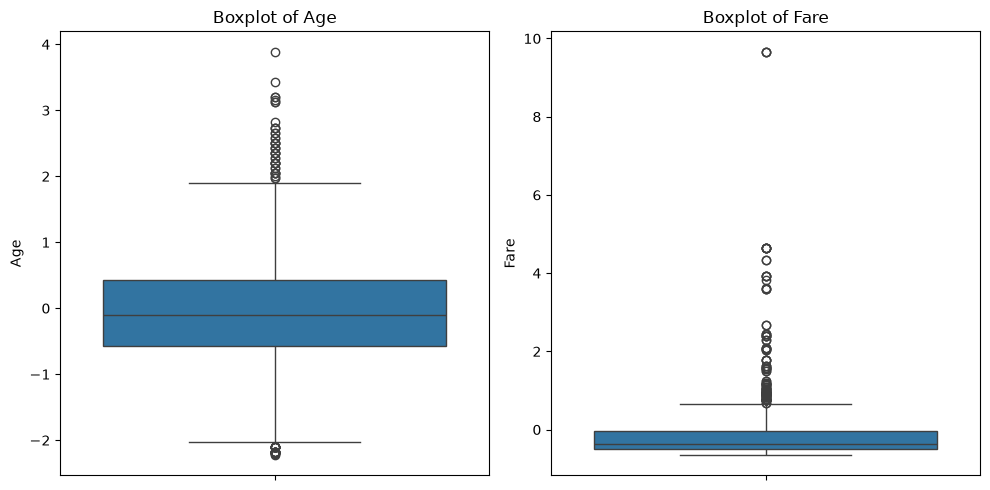

In [15]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["Age"])
plt.title("Boxplot of Age")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["Fare"])
plt.title("Boxplot of Fare")

plt.tight_layout()
plt.show()

## Step 6: Remove Extreme Fare Outliers

In [16]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

df = df[df["Fare"] <= upper_limit].copy()

print("\nDataset Shape After Outlier Removal:")
print(df.shape)

print("\nFinal Missing Values Check:")
print(df.isnull().sum())

print("\nTask 1 completed successfully!")


Dataset Shape After Outlier Removal:
(775, 12)

Final Missing Values Check:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked_Q     0
Embarked_S     0
dtype: int64

Task 1 completed successfully!
